In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
from google.colab import files

uploaded = files.upload()

Saving Advertising.csv to Advertising.csv


In [3]:
df = pd.read_csv('Advertising.csv')

df.head()

,Unnamed: 0,TV,Radio,Newspaper,Sales
0,1,230.1,37.8,69.2,22.1
1,2,44.5,39.3,45.1,10.4
2,3,17.2,45.9,69.3,9.3
3,4,151.5,41.3,58.5,18.5
4,5,180.8,10.8,58.4,12.9


In [4]:
df.shape

(200, 5)

In [5]:
df.columns

Index(['Unnamed: 0', 'TV', 'Radio', 'Newspaper', 'Sales'], dtype='object')

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Unnamed: 0  200 non-null    int64  
 1   TV          200 non-null    float64
 2   Radio       200 non-null    float64
 3   Newspaper   200 non-null    float64
 4   Sales       200 non-null    float64
dtypes: float64(4), int64(1)
memory usage: 7.9 KB


In [7]:
df.describe()

,Unnamed: 0,TV,Radio,Newspaper,Sales
count,200.000000,200.000000,200.000000,200.000000,200.000000
mean,100.500000,147.042500,23.264000,30.554000,14.022500
std,57.879185,85.854236,14.846809,21.778621,5.217457
min,1.000000,0.700000,0.000000,0.300000,1.600000
25%,50.750000,74.375000,9.975000,12.750000,10.375000
50%,100.500000,149.750000,22.900000,25.750000,12.900000
75%,150.250000,218.825000,36.525000,45.100000,17.400000
max,200.000000,296.400000,49.600000,114.000000,27.000000


In [8]:
df.isnull().sum()

,0
Unnamed: 0,0
TV,0
Radio,0
Newspaper,0
Sales,0


In [9]:
df.duplicated().sum()

np.int64(0)

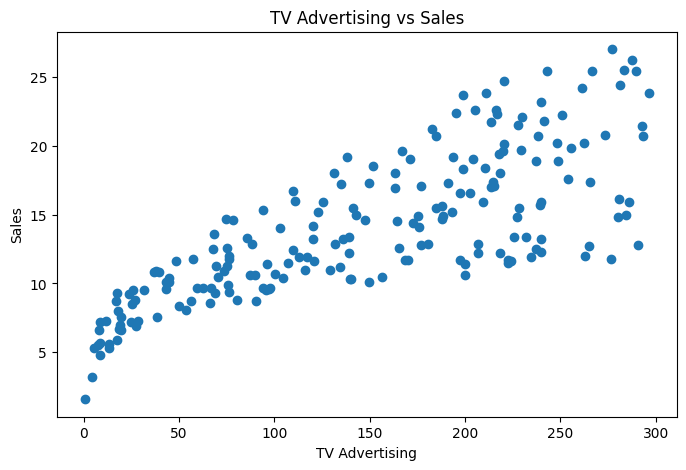

In [10]:
plt.figure(figsize=(8, 5))

plt.scatter(df['TV'], df['Sales'])

plt.xlabel('TV Advertising')
plt.ylabel('Sales')
plt.title('TV Advertising vs Sales')

plt.show()

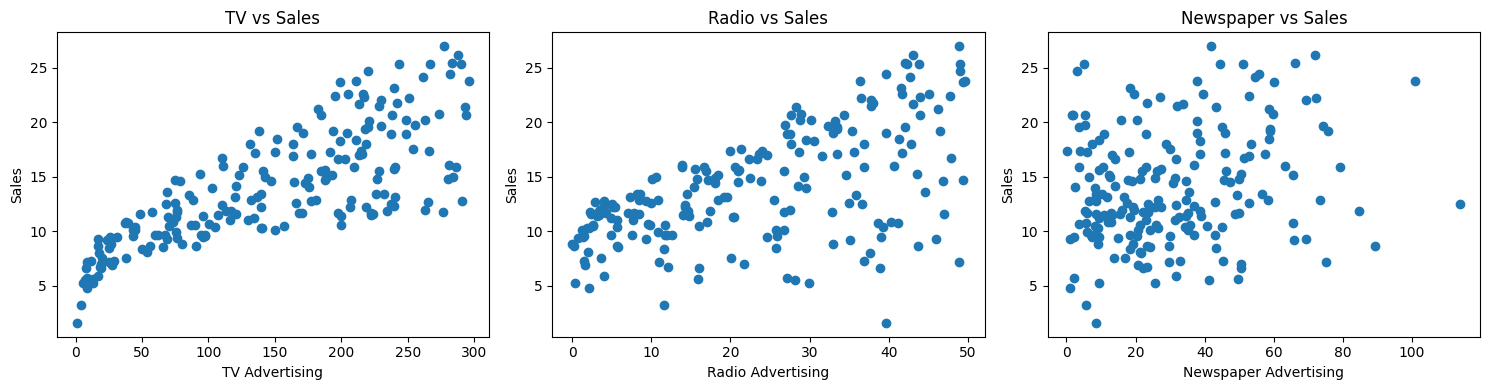

In [11]:
plt.figure(figsize=(15, 4))

plt.subplot(1, 3, 1)
plt.scatter(df['TV'], df['Sales'])
plt.xlabel('TV Advertising')
plt.ylabel('Sales')
plt.title('TV vs Sales')

plt.subplot(1, 3, 2)
plt.scatter(df['Radio'], df['Sales'])
plt.xlabel('Radio Advertising')
plt.ylabel('Sales')
plt.title('Radio vs Sales')

plt.subplot(1, 3, 3)
plt.scatter(df['Newspaper'], df['Sales'])
plt.xlabel('Newspaper Advertising')
plt.ylabel('Sales')
plt.title('Newspaper vs Sales')

plt.tight_layout()
plt.show()

In [12]:
correlation = df[['TV', 'Radio', 'Newspaper', 'Sales']].corr()

print(correlation)

                 TV     Radio  Newspaper     Sales
TV         1.000000  0.054809   0.056648  0.782224
Radio      0.054809  1.000000   0.354104  0.576223
Newspaper  0.056648  0.354104   1.000000  0.228299
Sales      0.782224  0.576223   0.228299  1.000000


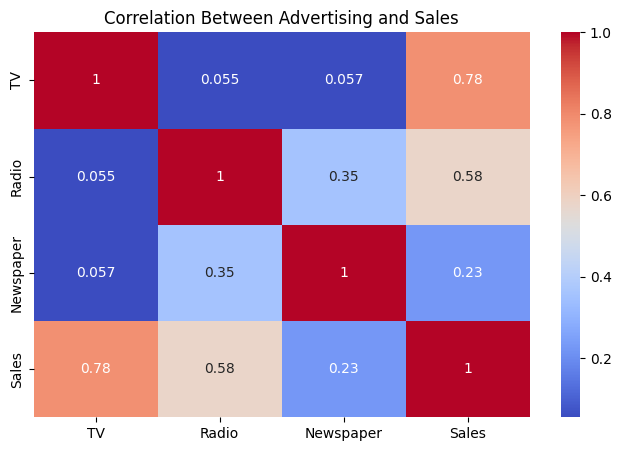

In [13]:
plt.figure(figsize=(8, 5))

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm'
)

plt.title('Correlation Between Advertising and Sales')
plt.show()

In [14]:
X = df[['TV', 'Radio', 'Newspaper']]

X.head()

,TV,Radio,Newspaper
0,230.1,37.8,69.2
1,44.5,39.3,45.1
2,17.2,45.9,69.3
3,151.5,41.3,58.5
4,180.8,10.8,58.4


In [15]:
y = df['Sales']

y.head()

,Sales
0,22.1
1,10.4
2,9.3
3,18.5
4,12.9


In [16]:
print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (200, 3)
y shape: (200,)


In [17]:
from sklearn.model_selection import train_test_split

In [18]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

In [19]:
print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training data: (160, 3)
Testing data: (40, 3)
Training target: (160,)
Testing target: (40,)


In [20]:
from sklearn.linear_model import LinearRegression

In [21]:
model = LinearRegression()

In [22]:
model.fit(X_train, y_train)

LinearRegression()

In [23]:
print("Coefficients:", model.coef_)
print("Intercept:", model.intercept_)

Coefficients: [0.04472952 0.18919505 0.00276111]
Intercept: 2.979067338122629


In [24]:
y_pred = model.predict(X_test)

print(y_pred)

[16.4080242  20.88988209 21.55384318 10.60850256 22.11237326 13.10559172
 21.05719192  7.46101034 13.60634581 15.15506967  9.04831992  6.65328312
 14.34554487  8.90349333  9.68959028 12.16494386  8.73628397 16.26507258
 10.27759582 18.83109103 19.56036653 13.25103464 12.33620695 21.30695132
  7.82740305  5.80957448 20.75753231 11.98138077  9.18349576  8.5066991
 12.46646769 10.00337695 21.3876709  12.24966368 18.26661538 20.13766267
 14.05514005 20.85411186 11.0174441   4.56899622]


In [25]:
comparison = pd.DataFrame({
    'Actual Sales': y_test,
    'Predicted Sales': y_pred
})

comparison.head(10)

,Actual Sales,Predicted Sales
95,16.9,16.408024
15,22.4,20.889882
30,21.4,21.553843
158,7.3,10.608503
128,24.7,22.112373
115,12.6,13.105592
69,22.3,21.057192
170,8.4,7.461010
174,11.5,13.606346
45,14.9,15.155070


In [27]:
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

In [28]:
r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)

print("Model Performance")
print("-----------------")
print("R2 Score:", r2)
print("MAE:", mae)
print("MSE:", mse)

Model Performance
-----------------
R2 Score: 0.899438024100912
MAE: 1.4607567168117603
MSE: 3.1740973539761033


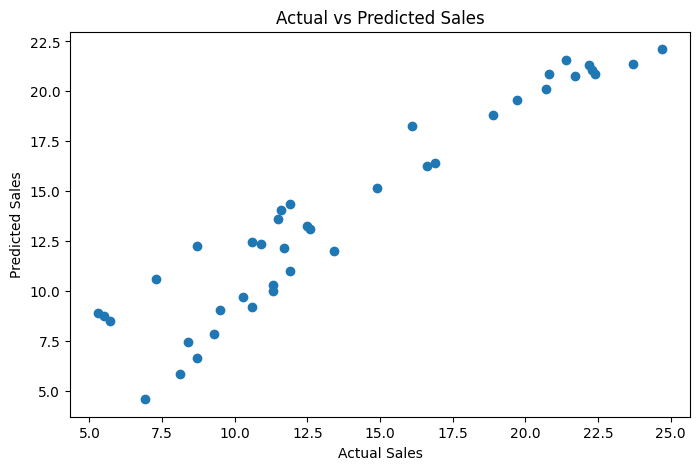

In [29]:
plt.figure(figsize=(8, 5))

plt.scatter(y_test, y_pred)

plt.xlabel('Actual Sales')
plt.ylabel('Predicted Sales')
plt.title('Actual vs Predicted Sales')

plt.show()

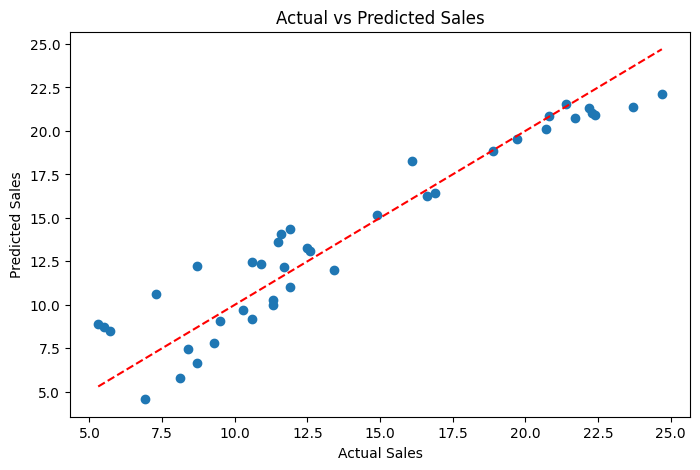

In [30]:
plt.figure(figsize=(8, 5))

plt.scatter(y_test, y_pred)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    'r--'
)

plt.xlabel('Actual Sales')
plt.ylabel('Predicted Sales')
plt.title('Actual vs Predicted Sales')

plt.show()

In [31]:
feature_names = ['TV', 'Radio', 'Newspaper']

coefficients = pd.DataFrame({
    'Advertising Platform': feature_names,
    'Coefficient': model.coef_
})

print(coefficients)

  Advertising Platform  Coefficient
0                   TV     0.044730
1                Radio     0.189195
2            Newspaper     0.002761


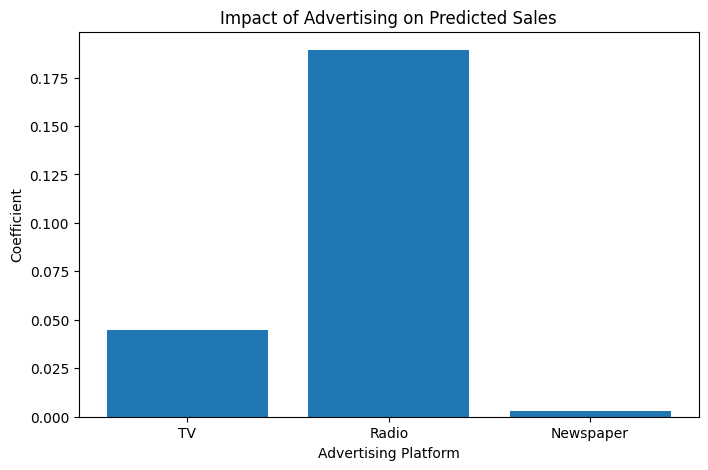

In [32]:
plt.figure(figsize=(8, 5))

plt.bar(
    coefficients['Advertising Platform'],
    coefficients['Coefficient']
)

plt.xlabel('Advertising Platform')
plt.ylabel('Coefficient')
plt.title('Impact of Advertising on Predicted Sales')

plt.show()

In [33]:
from sklearn.ensemble import RandomForestRegressor

In [34]:
rf_model = RandomForestRegressor(
    n_estimators=200,
    random_state=42
)

In [35]:
rf_model.fit(X_train, y_train)

RandomForestRegressor(n_estimators=200, random_state=42)

In [36]:
rf_pred = rf_model.predict(X_test)

print(rf_pred)

[17.7615 21.6665 20.6595  6.7395 23.096  13.5155 22.486   9.6625 11.8545
 15.504   7.4855  9.0335 12.1285  4.8615 10.5205 12.6515  6.5045 16.423
 11.3625 19.6895 19.981  12.9895 10.2715 22.009   9.9565  8.9615 22.2195
 12.6525 10.198   5.384  11.521  10.821  22.133   8.4955 15.315  20.4095
 12.137  20.662  12.309   7.5815]


In [37]:
rf_r2 = r2_score(y_test, rf_pred)

rf_mae = mean_absolute_error(y_test, rf_pred)

rf_mse = mean_squared_error(y_test, rf_pred)

print("Random Forest Performance")
print("-------------------------")
print("R2 Score:", rf_r2)
print("MAE:", rf_mae)
print("MSE:", rf_mse)

Random Forest Performance
-------------------------
R2 Score: 0.9818333477552758
MAE: 0.6287125000000021
MSE: 0.5734048312500032


In [38]:
results = pd.DataFrame({
    'Model': ['Linear Regression', 'Random Forest'],
    'R2 Score': [r2, rf_r2],
    'MAE': [mae, rf_mae],
    'MSE': [mse, rf_mse]
})

print(results)

               Model  R2 Score       MAE       MSE
0  Linear Regression  0.899438  1.460757  3.174097
1      Random Forest  0.981833  0.628713  0.573405


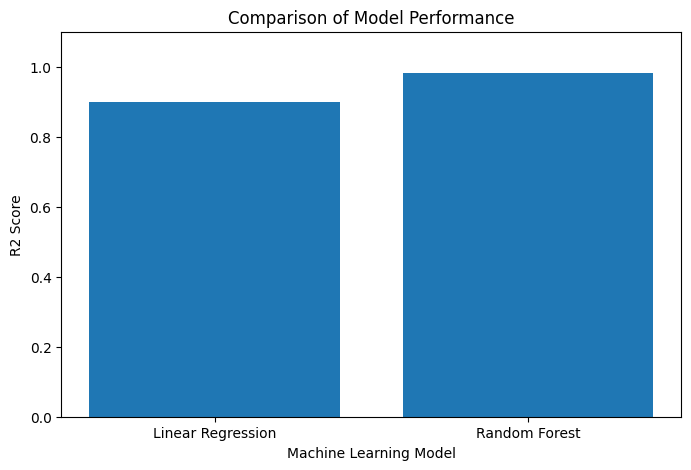

In [39]:
plt.figure(figsize=(8, 5))

plt.bar(results['Model'], results['R2 Score'])

plt.xlabel('Machine Learning Model')
plt.ylabel('R2 Score')
plt.title('Comparison of Model Performance')

plt.ylim(0, 1.1)

plt.show()

In [40]:
from sklearn.model_selection import cross_val_score

cv_scores = cross_val_score(
    rf_model,
    X,
    y,
    cv=5,
    scoring='r2'
)

print("Cross-validation scores:", cv_scores)
print("Average R2 Score:", cv_scores.mean())


Cross-validation scores: [0.98117941 0.98516573 0.97001686 0.96101347 0.98162447]
Average R2 Score: 0.975799987474933


In [41]:
new_advertising = pd.DataFrame({
    'TV': [200],
    'Radio': [30],
    'Newspaper': [40]
})

In [42]:
predicted_sales = rf_model.predict(new_advertising)

print("Predicted Sales:", predicted_sales[0])

Predicted Sales: 18.280500000000035
